In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("house_price_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values:")
print(df.isnull().sum())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975


\nMissing values:
House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64


In [3]:
X = df.drop(columns=["Price", "House_ID"], errors="ignore")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Number of original input columns:", X.shape[1])

Numerical features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']
Number of original input columns: 16


In [4]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_encoded = preprocessor.fit_transform(X)

# Convert sparse output, if any, to a dense array for PCA
if hasattr(X_encoded, "toarray"):
    X_encoded = X_encoded.toarray()

print("Shape after encoding:", X_encoded.shape)

Shape after encoding: (15025, 80)


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

print("Shape after standardization:", X_scaled.shape)
print("Mean of first 5 standardized features:",
      np.round(X_scaled.mean(axis=0)[:5], 3))
print("Standard deviation of first 5 features:",
      np.round(X_scaled.std(axis=0)[:5], 3))

Shape after standardization: (15025, 80)
Mean of first 5 standardized features: [ 0. -0. -0. -0. -0.]
Standard deviation of first 5 features: [1. 1. 1. 1. 1.]


In [6]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance Ratio": explained_variance,
    "Cumulative Explained Variance": cumulative_variance
})

display(variance_table.head(15))

,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.017492,0.017492
1,PC2,0.017233,0.034725
2,PC3,0.016958,0.051683
3,PC4,0.016762,0.068445
4,PC5,0.015894,0.084339
5,PC6,0.015563,0.099902
6,PC7,0.015457,0.115359
7,PC8,0.015358,0.130717
8,PC9,0.015237,0.145954
9,PC10,0.015050,0.161004


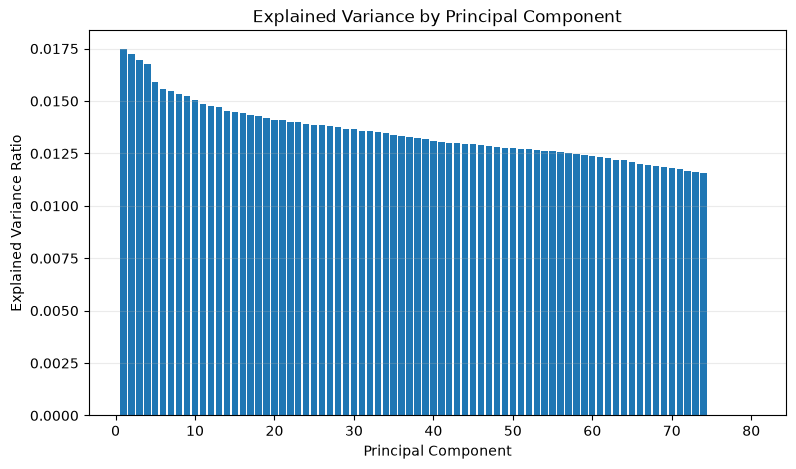

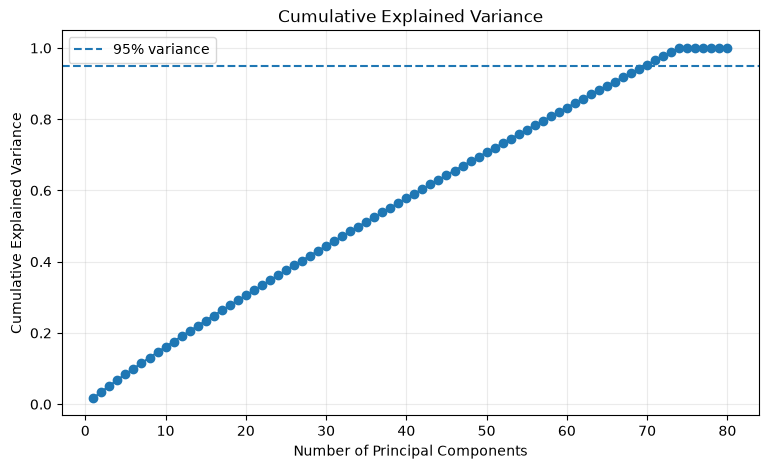

In [7]:
plt.figure(figsize=(9, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Component")
plt.grid(axis="y", alpha=0.25)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [8]:
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components required to retain at least 95% variance:",
      n_components_95)
print("Variance retained:",
      round(cumulative_variance[n_components_95 - 1] * 100, 2), "%")

Components required to retain at least 95% variance: 70
Variance retained: 95.34 %


In [9]:
pca = PCA(n_components=n_components_95)
X_reduced = pca.fit_transform(X_scaled)

pca_columns = [
    f"PC{i+1}" for i in range(n_components_95)
]

reduced_df = pd.DataFrame(
    X_reduced,
    columns=pca_columns,
    index=df.index
)

print("Original encoded shape:", X_scaled.shape)
print("Reduced shape:", X_reduced.shape)
display(reduced_df.head())

Original encoded shape: (15025, 80)
Reduced shape: (15025, 70)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC61,PC62,PC63,PC64,PC65,PC66,PC67,PC68,PC69,PC70
0,0.815900,0.025985,-1.153706,-1.872523,0.385268,-0.019322,0.580839,-1.128300,0.461427,-0.702731,...,-1.056659,0.879023,-2.058048,-0.202725,-0.840381,-0.165611,-1.107598,1.541457,-1.886429,1.273867
1,-0.190799,0.523995,0.124521,-0.129210,0.715492,0.381059,-1.549579,1.769698,2.341581,-0.913281,...,0.219314,0.664282,0.810018,-0.984739,0.413772,1.113228,-2.066766,1.328069,2.686858,-0.965967
2,-0.522815,0.088143,-1.283848,-0.788251,0.030392,-0.215857,-0.136831,-0.466804,2.053778,-2.728007,...,-0.124700,-0.496324,0.390306,-0.165057,-0.118815,0.534788,1.696340,1.889044,-1.265122,-0.210084
3,-1.035365,-1.307396,-0.239123,0.002886,-0.575976,-0.924915,0.804038,0.156882,-0.113771,-0.237961,...,-0.735773,0.850645,0.339880,0.269465,1.233290,-1.700345,-1.852092,-0.507868,-0.070248,-0.353363
4,-0.802195,-0.841841,0.220094,0.462239,-1.251857,-0.017296,1.857814,1.118529,0.274526,0.890984,...,-0.833802,0.554547,0.814540,-0.939889,0.862487,0.695555,-0.769217,1.719282,-0.167346,0.505634


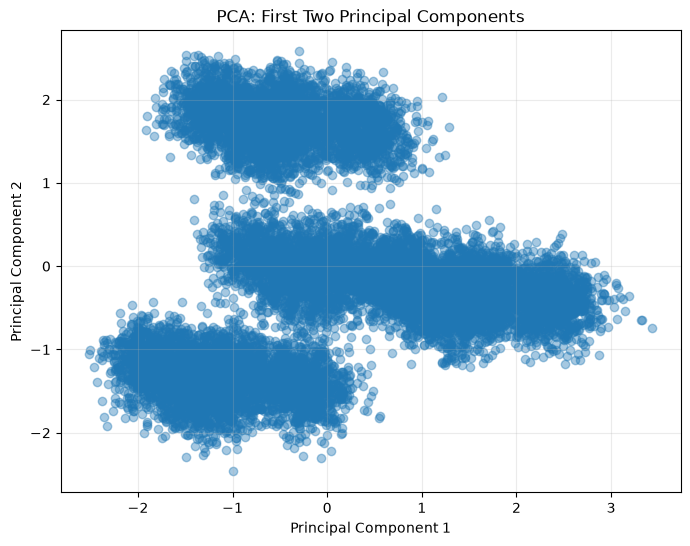

In [10]:
if X_reduced.shape[1] >= 2:
    plt.figure(figsize=(8, 6))
    plt.scatter(
        X_reduced[:, 0],
        X_reduced[:, 1],
        alpha=0.4
    )
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("PCA: First Two Principal Components")
    plt.grid(alpha=0.25)
    plt.show()
else:
    print("Only one component was selected; a 2D scatter plot is not available.")

In [11]:
original_dimensions = X_scaled.shape[1]
reduced_dimensions = X_reduced.shape[1]

print("Dimensions before PCA:", original_dimensions)
print("Dimensions after PCA:", reduced_dimensions)
print("Dimensions reduced by:", original_dimensions - reduced_dimensions)

if original_dimensions > 0:
    reduction_percentage = (
        (original_dimensions - reduced_dimensions) / original_dimensions
    ) * 100
    print("Dimensionality reduction:",
          round(reduction_percentage, 2), "%")

Dimensions before PCA: 80
Dimensions after PCA: 70
Dimensions reduced by: 10
Dimensionality reduction: 12.5 %
